# 05 — Modelling (Path B, Stages 4–6)

**Decision 3 from `01` §0.2:** should the tools team build a *stats → type* classifier to flag new designs whose
stats do not fit their type? A check is only useful if it is right far more often than a trivial guess, on
creatures it has **not** seen in any form. This notebook measures that honestly, then answers the review's two
modelling questions (best pair of stats; natural archetypes).

| § | Question |
|---|---|
| 5.1 | Features and leakage rules (Stage 4) |
| 5.2 | Baselines |
| 5.3 | How much does the validation protocol change the answer? (random vs family vs generation) |
| 5.4 | Is the honest score better than chance? |
| 5.5 | Which pair of stats separates types best? (review Task B) |
| 5.6 | Which types are recognisable at all? |
| 5.7 | Are there natural stat archetypes? (review Task C) |
| 5.8 | Model card |

In [1]:
import json, warnings
from pathlib import Path

import numpy as np
import pandas as pd

warnings.filterwarnings("ignore")
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 40)

ROOT = Path.cwd()
while not (ROOT / "archive" / "Pokemon.csv").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
ARCHIVE = ROOT / "archive"
RAW, PROC = ROOT / "data" / "raw", ROOT / "data" / "processed"
REPORTS, FIGS, MODELS = ROOT / "reports", ROOT / "reports" / "figures", ROOT / "models"
for p in (RAW, PROC, REPORTS, FIGS, MODELS):
    p.mkdir(parents=True, exist_ok=True)

KF_PATH = REPORTS / "_key_figures.json"
STATS = ["hp", "atk", "def", "spa", "spd", "spe"]
STAT_LABEL = {"hp": "HP", "atk": "Attack", "def": "Defense", "spa": "Sp. Atk", "spd": "Sp. Def", "spe": "Speed"}
SHARES = [f"sh_{s}" for s in STATS]


def _plain(v):
    if isinstance(v, dict):
        return {str(k): _plain(x) for k, x in v.items()}
    if hasattr(v, "item"):
        return v.item()
    if isinstance(v, (list, tuple)):
        return [_plain(x) for x in v]
    return v


def kf_update(**kw):
    """Append to reports/_key_figures.json — the only place the report reads numbers from."""
    kf = json.loads(KF_PATH.read_text(encoding="utf-8")) if KF_PATH.exists() else {}
    kf.update({k: _plain(v) for k, v in kw.items()})
    KF_PATH.write_text(json.dumps(kf, indent=1, sort_keys=True, ensure_ascii=False), encoding="utf-8")
    print(f"  _key_figures.json <- {', '.join(kw)}  ({len(kf)} figures total)")

import matplotlib as mpl
import matplotlib.pyplot as plt

# ---------------------------------------------------------------------------------------------
# DESIGN.md palette, defined inline (no local module imports — a fresh clone must run as-is).
#
# Validated with the dataviz skill's checker rather than eyeballed:
#   node scripts/validate_palette.js "#2251FF,#008A7E,#C1841C" --mode light --pairs all
#     PASS lightness | PASS chroma floor | PASS CVD separation (worst pair dE 12.5 protan)
#     PASS normal-vision separation (21.1) | PASS contrast >= 3:1 on white
# Charts here never need more than three identity colours: Blue = the focus series, Teal = the
# second series, Amber = reference lines / thresholds. Everything else is Grey context.
# DESIGN.md's Teal #00857C FAILS the chroma floor (C = 0.097 < 0.10, reads as grey), so it is
# nudged to #008A7E on the same hue. Navy is text ink only — never a series fill.
# Diverging (type signature heatmap): Amber (below average) <- light grey -> Blue (above average).
# ---------------------------------------------------------------------------------------------
NAVY, BLUE, TEAL, AMBER, CYAN = "#051C2C", "#2251FF", "#008A7E", "#C1841C", "#00A9F4"
SLATE, GREY, GRID, LIGHT = "#7F93A6", "#9FADB8", "#E9ECEF", "#D5DCE2"
C_FOCUS, C_SECOND, C_REF, C_CONTEXT = BLUE, TEAL, AMBER, GREY


def apply_style():
    mpl.rcParams.update({
        "figure.dpi": 130, "savefig.dpi": 130, "figure.facecolor": "white",
        "axes.facecolor": "white", "savefig.facecolor": "white",
        "font.family": "sans-serif", "font.sans-serif": ["Arial", "Helvetica", "DejaVu Sans"],
        "font.size": 9, "text.color": NAVY,
        "axes.titlelocation": "left", "axes.titlesize": 10.5, "axes.titleweight": "bold",
        "axes.titlecolor": NAVY, "axes.titlepad": 10,
        "axes.labelsize": 9, "axes.labelcolor": SLATE, "axes.edgecolor": GREY,
        "axes.spines.top": False, "axes.spines.right": False, "axes.linewidth": 0.8,
        "xtick.color": SLATE, "ytick.color": SLATE, "xtick.labelsize": 8.5, "ytick.labelsize": 8.5,
        "grid.color": GRID, "grid.linewidth": 0.8, "axes.grid": True, "axes.grid.axis": "y",
        "axes.axisbelow": True,
        "legend.frameon": False, "legend.fontsize": 8.5,
        "lines.linewidth": 2.0, "lines.markersize": 8,
    })


apply_style()
SOURCE = "Pokemon.csv (Kaggle 'Pokemon with stats', main-series games, Generations 1–6)"


def finish(fig, note=""):
    """Every exhibit carries its source line — STRUCTURE.md Step 7.3. Placed under the lowest
    artist (axis labels, outside legends), so it never collides with them."""
    fig.canvas.draw()
    r = fig.canvas.get_renderer()
    y0 = min(ax.get_tightbbox(r).transformed(fig.transFigure.inverted()).y0 for ax in fig.axes)
    fig.text(0.005, y0 - 0.12 / fig.get_figheight(), f"Source: {SOURCE}" + (f" · {note}" if note else ""),
             fontsize=7, color=SLATE, ha="left", va="top")


def suptitle(fig, text, y=1.04):
    fig.suptitle(text, x=0.005, ha="left", fontsize=11.5, fontweight="bold", color=NAVY, y=y)


def save(fig, name):
    fig.savefig(FIGS / name, bbox_inches="tight", facecolor="white")
    print(f"  saved reports/figures/{name}")

import itertools
from sklearn.model_selection import StratifiedKFold, GroupKFold, LeaveOneGroupOut, cross_val_predict
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import accuracy_score, f1_score, roc_auc_score, recall_score, silhouette_score
from sklearn.cluster import KMeans

df = pd.read_parquet(PROC / "pokemon_clean.parquet")
sp = df[df.is_species].reset_index(drop=True)
y = sp.type1.astype(str).to_numpy()
y_all = df.type1.astype(str).to_numpy()
fam, gen = sp.family.to_numpy(), sp.generation.to_numpy()
signatures = pd.read_csv(REPORTS / "_signatures.csv")
SIG_TYPES = list(dict.fromkeys(signatures.loc[signatures.signature, "type"]))
SEEDS = [42, 7, 101, 2024, 31337]
print(f"{len(sp)} species · {len(np.unique(y))} classes · {sp.family.nunique()} families · seeds {SEEDS}")

721 species · 18 classes · 360 families · seeds [42, 7, 101, 2024, 31337]


## 5.1 Features and leakage rules (Stage 4)

| Decision | Rationale |
|---|---|
| **Main features: the six stat shares** | Shape, with power held constant. `04` showed type moves shape (up to 28% of a share's variation) far more than power (6% of Total) |
| Comparison features: the six raw stats | To show what magnitude adds (mostly legendary and stage noise) |
| **`total` never alongside the six stats** | It is their exact sum: redundant for trees, collinear for linear models (review §6) |
| **Target: `type1` of the 721 species** | Forms are dropped. They copy their species' number and type, so they would be free answers |
| `type2`, `generation`, `legendary`, name, dex | Excluded: either not available for a new design's check, or (dex) the key to family leakage |
| Scaling | Standardised inside the pipeline for logistic regression; not needed for the random forest |

Models: **multinomial logistic regression** (the baseline model) and a **random forest** (300 trees,
`min_samples_leaf = 2`). Both are fitted inside each fold, so no information crosses the split.

In [2]:
X_sh = sp[SHARES].to_numpy()
X_raw = sp[STATS].to_numpy(float)
X_sh_all = df[SHARES].to_numpy()


def lr():
    return make_pipeline(StandardScaler(), LogisticRegression(max_iter=5000))


def rf(seed=RANDOM_STATE, trees=300):
    return RandomForestClassifier(trees, min_samples_leaf=2, random_state=seed, n_jobs=-1)


print("feature correlation check — shares sum to 1, so one is redundant for LR; the L2 penalty handles it:")
print(f"  max |corr| between shares: {np.abs(np.corrcoef(X_sh.T)[~np.eye(6, dtype=bool)]).max():.2f}")

feature correlation check — shares sum to 1, so one is redundant for LR; the L2 penalty handles it:
  max |corr| between shares: 0.56


## 5.2 Baselines

In [3]:
counts = pd.Series(y).value_counts()
maj_acc = counts.iloc[0] / len(y)
maj_f1 = f1_score(y, np.full(len(y), counts.index[0]), average="macro")
prior_acc = float(((counts / len(y)) ** 2).sum())
print(f"majority class                : always '{counts.index[0]}'  -> accuracy {maj_acc:.1%}, macro-F1 {maj_f1:.3f}")
print(f"guess in proportion to classes: expected accuracy {prior_acc:.1%}")
print(f"uniform guess over 18 types   : {1/18:.1%}")

majority class                : always 'Water'  -> accuracy 14.6%, macro-F1 0.014
guess in proportion to classes: expected accuracy 7.9%
uniform guess over 18 types   : 5.6%


The bar any check must clear is **14.6%**, the score of always answering "Water". Uniform guessing (5.6%) is not the
right comparison, because the classes are imbalanced.

## 5.3 The validation protocol decides the answer

Four ways to estimate the same model's accuracy, from the most to the least leaky:

1. **Random split, all 800 rows**: forms of a species can sit on both sides.
2. **Random split, 721 species**: forms removed, but evolution siblings still straddle the split.
3. **Family-grouped split, 721 species**: every family proxy (`02` §2.4) is wholly in train or in test. *The honest protocol.*
4. **Leave one generation out**: train on five generations, predict the sixth, the way a new roster would be checked.

Each is run with five seeds (fold assignment and forest seed both change).

In [4]:
def run(protocol, model_name, seed):
    model = (lr() if model_name.startswith("LR") else rf(seed))
    X = X_raw if "raw" in model_name else X_sh
    if protocol == "random, 800 rows":
        p = cross_val_predict(model, X_sh_all if "raw" not in model_name else df[STATS].to_numpy(float), y_all,
                              cv=StratifiedKFold(5, shuffle=True, random_state=seed))
        yt = y_all
    elif protocol == "random, 721 species":
        p = cross_val_predict(model, X, y, cv=StratifiedKFold(5, shuffle=True, random_state=seed)); yt = y
    elif protocol == "family-grouped":
        p = cross_val_predict(model, X, y, cv=GroupKFold(5, shuffle=True, random_state=seed), groups=fam); yt = y
    else:
        p = cross_val_predict(model, X, y, cv=LeaveOneGroupOut(), groups=gen); yt = y
    return accuracy_score(yt, p), f1_score(yt, p, average="macro"), p


PROTOCOLS = ["random, 800 rows", "random, 721 species", "family-grouped", "leave one generation out"]
MODEL_NAMES = ["RF · shares", "LR · shares", "RF · raw stats"]
res, preds = [], {}
for prot in PROTOCOLS:
    for mname in MODEL_NAMES:
        for s in SEEDS:
            if prot == "leave one generation out" and mname.startswith("LR") and s != SEEDS[0]:
                continue                                        # deterministic: one run is enough
            acc, f1, p = run(prot, mname, s)
            res.append({"protocol": prot, "model": mname, "seed": s, "accuracy": acc, "macro_f1": f1})
            preds[(prot, mname, s)] = p
res = pd.DataFrame(res)
summary = (res.groupby(["protocol", "model"], sort=False)
              .agg(accuracy=("accuracy", "mean"), acc_sd=("accuracy", "std"), macro_f1=("macro_f1", "mean"), runs=("seed", "size"))
              .round(3))
summary

accuracy  acc_sd  macro_f1  runs
protocol                 model                                           
random, 800 rows         RF · shares        0.344   0.006     0.289     5
                         LR · shares        0.230   0.007     0.133     5
                         RF · raw stats     0.250   0.007     0.180     5
random, 721 species      RF · shares        0.340   0.008     0.277     5
                         LR · shares        0.249   0.006     0.142     5
                         RF · raw stats     0.221   0.011     0.136     5
family-grouped           RF · shares        0.212   0.018     0.145     5
                         LR · shares        0.209   0.018     0.112     5
                         RF · raw stats     0.213   0.017     0.130     5
leave one generation out RF · shares        0.205   0.004     0.140     5
                         LR · shares        0.230     NaN     0.127     1
                         RF · raw stats     0.222   0.009     0.130     5

In [5]:
honest = summary.loc[("family-grouped", "RF · shares")]
leaky = summary.loc[("random, 721 species", "RF · shares")]
leaky800 = summary.loc[("random, 800 rows", "RF · shares")]
logo = summary.loc[("leave one generation out", "RF · shares")]
p0 = preds[("family-grouped", "RF · shares", SEEDS[0])]
hr = res[(res.protocol == "family-grouped") & (res.model == "RF · shares")].accuracy
print(f"honest (family-grouped) RF on shares: accuracy {honest.accuracy:.1%} ± {honest.acc_sd:.1%} across seeds "
      f"(range {hr.min():.1%}–{hr.max():.1%}); macro-F1 {honest.macro_f1:.3f}")
print(f"random split on species            : {leaky.accuracy:.1%}  -> overstated by {(leaky.accuracy - honest.accuracy)*100:.1f} points")
print(f"random split on all 800 rows        : {leaky800.accuracy:.1%}")
print(f"leave one generation out            : {logo.accuracy:.1%}")
print(f"lift over the majority baseline (honest): {(honest.accuracy - maj_acc)*100:+.1f} points")

honest (family-grouped) RF on shares: accuracy 21.2% ± 1.8% across seeds (range 19.6%–24.3%); macro-F1 0.145
random split on species            : 34.0%  -> overstated by 12.8 points
random split on all 800 rows        : 34.4%
leave one generation out            : 20.5%
lift over the majority baseline (honest): +6.6 points


### Exhibit 8 — A random split overstates type-from-stats accuracy by 13 points; honestly validated, stats name the type about one time in five

  saved reports/figures/ex08_protocols.png


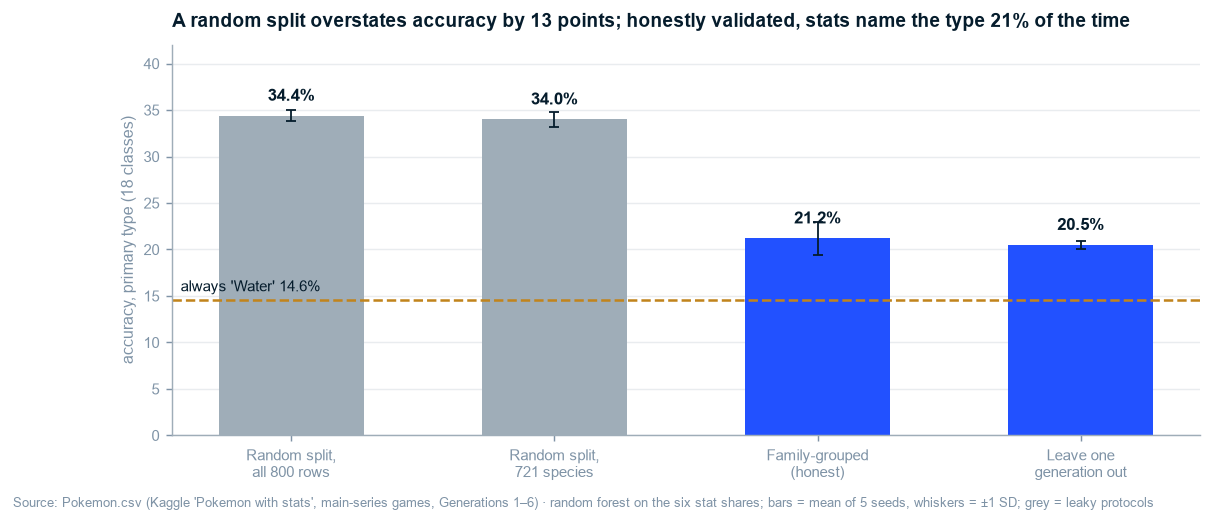

In [6]:
rf_sh = summary.xs("RF · shares", level="model").loc[PROTOCOLS]
labels = ["Random split,\nall 800 rows", "Random split,\n721 species", "Family-grouped\n(honest)", "Leave one\ngeneration out"]
fig, ax = plt.subplots(figsize=(10.2, 3.9))
colors = [GREY, GREY, BLUE, BLUE]
ax.bar(labels, rf_sh.accuracy * 100, color=colors, width=0.55, yerr=rf_sh.acc_sd * 100,
       error_kw=dict(ecolor=NAVY, elinewidth=1, capsize=3))
for x, v in enumerate(rf_sh.accuracy):
    ax.text(x, v * 100 + 1.6, f"{v:.1%}", ha="center", fontsize=9.5, color=NAVY, fontweight="bold")
ax.axhline(maj_acc * 100, color=AMBER, ls="--", lw=1.4)
ax.text(-0.42, maj_acc * 100 + 0.6, f"always 'Water' {maj_acc:.1%}", ha="left", va="bottom", fontsize=8.2, color=NAVY)
ax.set_ylim(0, 42); ax.set_ylabel("accuracy, primary type (18 classes)")
ax.set_title(f"A random split overstates accuracy by {(leaky.accuracy - honest.accuracy)*100:.0f} points; honestly "
             f"validated, stats name the type {honest.accuracy:.0%} of the time")
finish(fig, "random forest on the six stat shares; bars = mean of 5 seeds, whiskers = ±1 SD; grey = leaky protocols")
save(fig, "ex08_protocols.png")
plt.show()

**So What:** the same model scores about a third of species correctly under a random split, and about one in five when
evolution families are kept together. The gap is memorisation: with a sibling in the training set, the model recognises
the family's shape and copies its type. Predicting a whole unseen generation gives the same answer as the family split,
which confirms the honest number. That number beats "always Water" by about six points.

**Implication:** a stats → type design check would be wrong four times out of five on a new creature. That is a **no-go**.
The review's "stratified split" advice would have reported the inflated number. On this roster, any model must be validated
by family or by generation.

## 5.4 Is the honest score better than chance?

In [7]:
N_PERM = 40
perm = []
for i in range(N_PERM):
    yp = np.random.default_rng(1000 + i).permutation(y)
    pp = cross_val_predict(rf(trees=200), X_sh, yp, cv=GroupKFold(5, shuffle=True, random_state=RANDOM_STATE), groups=fam)
    perm.append(accuracy_score(yp, pp))
perm = np.array(perm)
real0 = accuracy_score(y, p0)
p_perm = (1 + (perm >= real0).sum()) / (N_PERM + 1)
print(f"honest run (seed {SEEDS[0]}) {real0:.1%} vs {N_PERM} label-shuffled runs on the same folds: "
      f"mean {perm.mean():.1%}, max {perm.max():.1%}; p = {p_perm:.3f} (the smallest possible with {N_PERM} runs)")
print(f"every honest run ({hr.min():.1%}–{hr.max():.1%}) beats every shuffled run")

honest run (seed 42) 24.3% vs 40 label-shuffled runs on the same folds: mean 10.4%, max 13.0%; p = 0.024 (the smallest possible with 40 runs)
every honest run (19.6%–24.3%) beats every shuffled run


The signal is real. The lowest of the five honest runs beats the best of 40 shuffled-label runs, and a forest on
shuffled labels scores *below* the majority baseline, because it spreads its guesses across classes. Stats do carry type
information. There just isn't much of it.

## 5.5 Which pair of stats separates types best? (review Task B)

The dataset was published with the premise that type "cannot be inferred from Attack and Defense". All 15 pairs of raw stats
were tested with both models, family-grouped, over the same five seeds; each pair's score is the better of the two
models' five-seed means.

In [8]:
rows = []
for a, b in itertools.combinations(STATS, 2):
    Xp = sp[[a, b]].to_numpy(float)
    for s in SEEDS:
        for nm, mk in [("LR", lr), ("RF", lambda: RandomForestClassifier(200, min_samples_leaf=5, random_state=s, n_jobs=-1))]:
            pr = cross_val_predict(mk(), Xp, y, cv=GroupKFold(5, shuffle=True, random_state=s), groups=fam)
            rows.append({"pair": f"{STAT_LABEL[a]} × {STAT_LABEL[b]}", "model": nm, "seed": s,
                         "acc": accuracy_score(y, pr), "f1": f1_score(y, pr, average="macro")})
pr_ = pd.DataFrame(rows).groupby(["pair", "model"]).agg(acc=("acc", "mean"), sd=("acc", "std"), f1=("f1", "mean")).unstack("model")
pairs = pd.DataFrame({"pair": pr_.index,
                      "acc_LR": pr_[("acc", "LR")].to_numpy(), "acc_RF": pr_[("acc", "RF")].to_numpy(),
                      "f1_LR": pr_[("f1", "LR")].to_numpy(), "f1_RF": pr_[("f1", "RF")].to_numpy()})
pairs["best_acc"] = pairs[["acc_LR", "acc_RF"]].max(axis=1)
pairs["seed_sd"] = np.where(pairs.acc_LR >= pairs.acc_RF, pr_[("sd", "LR")].to_numpy(), pr_[("sd", "RF")].to_numpy())
pairs = pairs.sort_values("best_acc", ascending=False).reset_index(drop=True)
pairs["rank"] = np.arange(1, len(pairs) + 1)
pairs.to_csv(REPORTS / "_pairs.csv", index=False)
ad_rank = int(pairs.loc[pairs.pair == "Attack × Defense", "rank"].iloc[0])
pairs.round(3)

,pair,acc_LR,acc_RF,f1_LR,f1_RF,best_acc,seed_sd,rank
0,Attack × Sp. Atk,0.193,0.170,0.070,0.090,0.193,0.013,1
1,Sp. Atk × Speed,0.178,0.166,0.047,0.073,0.178,0.008,2
2,Defense × Sp. Atk,0.174,0.174,0.058,0.084,0.174,0.009,3
3,Attack × Defense,0.169,0.141,0.052,0.082,0.169,0.016,4
4,HP × Sp. Atk,0.164,0.168,0.051,0.076,0.168,0.012,5
5,Defense × Speed,0.164,0.157,0.048,0.081,0.164,0.012,6
6,Sp. Atk × Sp. Def,0.163,0.137,0.039,0.067,0.163,0.010,7
7,Defense × Sp. Def,0.150,0.130,0.049,0.069,0.150,0.009,8
8,HP × Speed,0.125,0.143,0.040,0.070,0.143,0.008,9
9,HP × Sp. Def,0.126,0.141,0.037,0.064,0.141,0.007,10


### Exhibit 9 — No pair of stats identifies type: the best pair beats "always Water" by a few points

  saved reports/figures/ex09_pairs.png


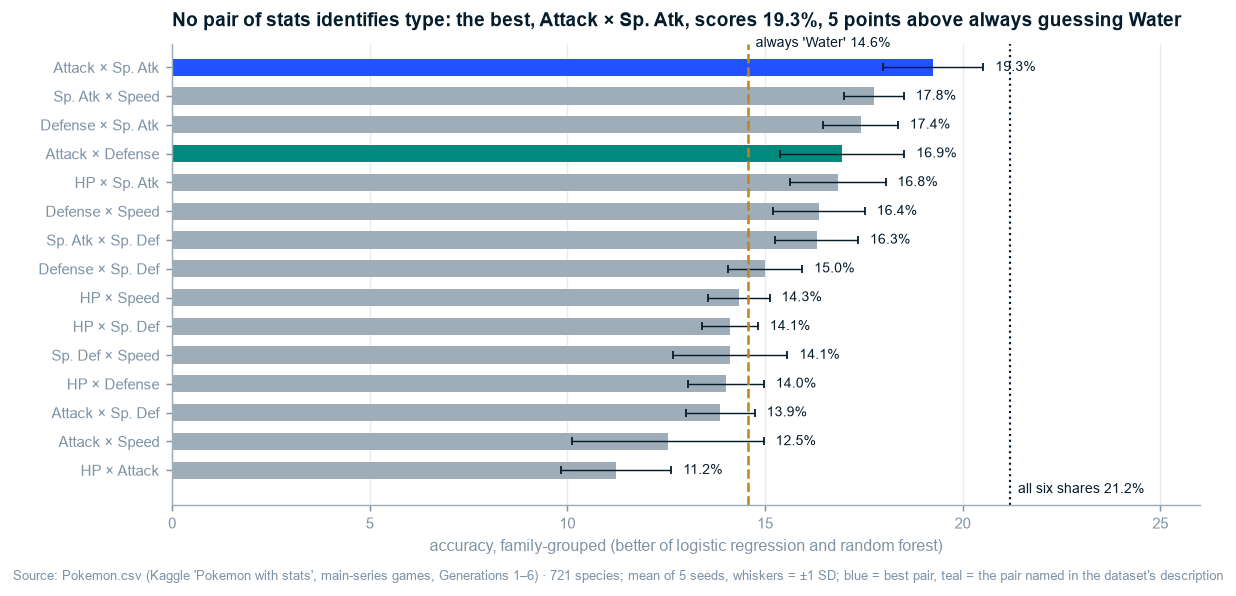

In [9]:
fig, ax = plt.subplots(figsize=(10.2, 4.6))
pp_ = pairs.iloc[::-1].reset_index(drop=True)
cols = [BLUE if r == 1 else (TEAL if p == "Attack × Defense" else GREY) for p, r in zip(pp_.pair, pp_["rank"])]
ax.barh(pp_.pair, pp_.best_acc * 100, color=cols, height=0.6, xerr=pp_.seed_sd * 100,
        error_kw=dict(ecolor=NAVY, elinewidth=0.8, capsize=2))
for yy, v in enumerate(pp_.best_acc):
    ax.text(v * 100 + pp_.seed_sd[yy] * 100 + 0.3, yy, f"{v:.1%}", va="center", fontsize=8, color=NAVY)
ax.axvline(maj_acc * 100, color=AMBER, ls="--", lw=1.4)
ax.text(maj_acc * 100 + 0.2, len(pp_) - 0.4, f"always 'Water' {maj_acc:.1%}", fontsize=8, color=NAVY, va="bottom")
ax.axvline(honest.accuracy * 100, color=NAVY, ls=":", lw=1.2)
ax.text(honest.accuracy * 100 + 0.2, -0.9, f"all six shares {honest.accuracy:.1%}", fontsize=8, color=NAVY, va="bottom")
ax.set_xlim(0, 26); ax.set_ylim(-1.2, len(pp_) - 0.2)
ax.grid(axis="x"); ax.grid(axis="y", visible=False)
ax.set_xlabel("accuracy, family-grouped (better of logistic regression and random forest)")
best = pairs.iloc[0]
ax.set_title(f"No pair of stats identifies type: the best, {best.pair}, scores {best.best_acc:.1%}, "
             f"{(best.best_acc - maj_acc)*100:.0f} points above always guessing Water")
finish(fig, "721 species; mean of 5 seeds, whiskers = ±1 SD; blue = best pair, teal = the pair named in the dataset's description")
save(fig, "ex09_pairs.png")
plt.show()

**So What:** the dataset's premise holds, but not because Attack and Defense are a poor choice: they are among the
better pairs. It holds because **no** two stats separate types much better than "always Water". The pairs at the top
are within seed noise of each other, and using all six shares adds only a little more.

**Implication:** the review's suggested "2D scatter with decision regions" teaching visual would show overlapping
clouds, not regions. That is the correct lesson: type is not written into any two stats.

## 5.6 Which types are recognisable at all?

One-vs-rest AUC per type, from logistic regression on shares, family-grouped. An AUC of 0.5 is a coin flip. The
interval resamples families.

In [10]:
proba = cross_val_predict(lr(), X_sh, y, cv=GroupKFold(5, shuffle=True, random_state=RANDOM_STATE), groups=fam,
                          method="predict_proba")
classes = np.unique(y)
fams_u = np.unique(fam)
idx_by_f = {f: np.where(fam == f)[0] for f in fams_u}
rng = np.random.default_rng(RANDOM_STATE)
boot_idx = [np.concatenate([idx_by_f[f] for f in rng.choice(fams_u, len(fams_u))]) for _ in range(1000)]
auc = []
for i, c in enumerate(classes):
    yt = (y == c)
    bs = [roc_auc_score(yt[b], proba[b, i]) for b in boot_idx if 0 < yt[b].sum() < len(b)]
    auc.append({"type": c, "n": int(yt.sum()), "auc": roc_auc_score(yt, proba[:, i]),
                "lo": np.percentile(bs, 2.5), "hi": np.percentile(bs, 97.5), "signature": c in SIG_TYPES})
auc = pd.DataFrame(auc).sort_values("auc", ascending=False).reset_index(drop=True)
rec = pd.Series(recall_score(y, p0, labels=classes, average=None), index=classes)
auc["recall_rf"] = auc.type.map(rec)
auc.to_csv(REPORTS / "_type_auc.csv", index=False)
GOOD = 0.75
n_good = int((auc.auc >= GOOD).sum())
auc.round(3)

,type,n,auc,lo,hi,signature,recall_rf
0,Steel,22,0.866,0.784,0.925,True,0.364
1,Fighting,25,0.831,0.710,0.929,True,0.240
2,Normal,93,0.827,0.775,0.877,True,0.581
3,Fairy,17,0.816,0.627,0.950,True,0.118
4,Psychic,47,0.786,0.684,0.874,True,0.255
5,Electric,36,0.766,0.671,0.864,True,0.306
6,Ground,30,0.763,0.655,0.856,True,0.233
7,Rock,41,0.747,0.656,0.855,True,0.293
8,Fire,47,0.722,0.624,0.807,True,0.298
9,Dragon,24,0.637,0.534,0.731,False,0.000


### Exhibit 10 — Only a handful of types are recognisable from their stats, all of them signature types; several are no better than a coin flip

  saved reports/figures/ex10_type_auc.png


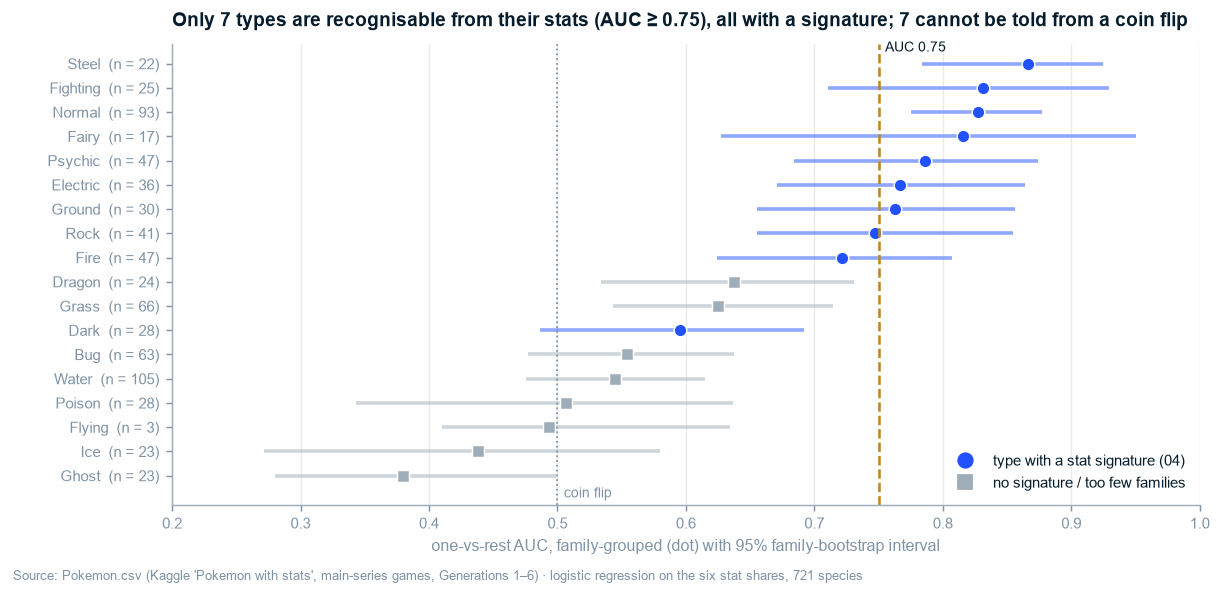

In [11]:
fig, ax = plt.subplots(figsize=(10.2, 4.6))
a_ = auc.iloc[::-1].reset_index(drop=True)
for yy, r in a_.iterrows():
    c = BLUE if r.signature else GREY
    ax.hlines(yy, r.lo, r.hi, color=c, lw=2, alpha=0.5)
    ax.plot(r.auc, yy, marker="o" if r.signature else "s", color=c, ms=7, mec="white", mew=0.8, ls="none")
ax.set_yticks(range(len(a_)), [f"{t}  (n = {n})" for t, n in zip(a_.type, a_.n)])
ax.axvline(0.5, color=SLATE, lw=1, ls=":")
ax.axvline(GOOD, color=AMBER, lw=1.4, ls="--")
ax.text(GOOD + 0.005, len(a_) - 0.5, f"AUC {GOOD}", color=NAVY, fontsize=8)
ax.text(0.505, -0.9, "coin flip", color=SLATE, fontsize=8)
ax.plot([], [], marker="o", color=BLUE, ls="none", label="type with a stat signature (04)")
ax.plot([], [], marker="s", color=GREY, ls="none", label="no signature / too few families")
ax.legend(loc="lower right")
ax.set_xlim(0.2, 1.0); ax.set_ylim(-1.2, len(a_) - 0.2)
ax.grid(axis="x"); ax.grid(axis="y", visible=False)
ax.set_xlabel("one-vs-rest AUC, family-grouped (dot) with 95% family-bootstrap interval")
ax.set_title(f"Only {n_good} types are recognisable from their stats (AUC ≥ {GOOD}), all with a signature; "
             f"{int((auc.lo <= 0.5).sum())} cannot be told from a coin flip")
finish(fig, "logistic regression on the six stat shares, 721 species")
save(fig, "ex10_type_auc.png")
plt.show()

**So What:** recognisability follows the signatures from `04`. Every type above the line has one (Steel's Defense,
Fighting's Attack, Normal's HP, Psychic's and Fairy's special bias, Electric's Speed, Ground's physical bulk), and Rock
and Fire fall just short. Water, Bug, Poison, Ice and Flying have intervals that reach a coin flip, and so does Dark,
whose signature is weak. Ghost scores *below* 0.5: its families (Gengar, Dusclops, Spiritomb…) are so unlike each other
that what the model learns from some Ghost lines points away from the rest.

**Implication:** a narrow, *soft* check is defensible for the types that clear the line: "this Steel design has less
Defense than 9 in 10 Steel creatures". That is a warning a designer can override, not a classifier deciding type. For
every other type, any check would flag noise.

## 5.7 Are there natural stat archetypes? (review Task C)

**Hypothesis (review):** natural clusters exist (tank, sweeper, glass cannon, balanced). Test: k-means on standardised
shares for k = 2–8, against a null where each share column is shuffled independently (same distributions, no structure),
50 nulls per k.

In [12]:
Z = StandardScaler().fit_transform(X_sh)
arch = []
for k in range(2, 9):
    real_s = silhouette_score(Z, KMeans(k, n_init=10, random_state=RANDOM_STATE).fit_predict(Z))
    nulls = []
    for i in range(50):
        r_ = np.random.default_rng(i)
        Zn = np.column_stack([r_.permutation(Z[:, j]) for j in range(Z.shape[1])])
        nulls.append(silhouette_score(Zn, KMeans(k, n_init=4, random_state=RANDOM_STATE).fit_predict(Zn)))
    arch.append({"k": k, "silhouette": real_s, "null_mean": np.mean(nulls), "null_max": np.max(nulls)})
arch = pd.DataFrame(arch)
arch["margin_over_null_max"] = arch.silhouette - arch.null_max
arch.round(3)

,k,silhouette,null_mean,null_max,margin_over_null_max
0,2,0.197,0.124,0.151,0.046
1,3,0.195,0.129,0.144,0.051
2,4,0.205,0.132,0.145,0.059
3,5,0.185,0.140,0.151,0.034
4,6,0.192,0.145,0.152,0.040
5,7,0.186,0.145,0.155,0.031
6,8,0.185,0.139,0.150,0.035


In [13]:
best_k = int(arch.loc[arch.silhouette.idxmax(), "k"])
lab = KMeans(best_k, n_init=10, random_state=RANDOM_STATE).fit_predict(Z)
prof = sp.assign(cluster=lab).groupby("cluster")[SHARES].mean().mul(100).round(1)
prof.columns = [STAT_LABEL[c[3:]] for c in prof.columns]
prof["n"] = np.bincount(lab)
print(f"best k by silhouette: {best_k} (silhouette {arch.silhouette.max():.3f}); profiles (% of Total):")
prof

best k by silhouette: 4 (silhouette 0.205); profiles (% of Total):


,HP,Attack,Defense,Sp. Atk,Sp. Def,Speed,n
cluster,,,,,,,
0,16.1,13.9,18.3,18.2,21.3,12.2,193
1,16.8,22.3,20.5,12.7,14.5,13.3,214
2,15.1,17.5,13.9,17.9,14.9,20.6,293
3,35.4,14.8,11.2,13.0,15.1,10.5,21


The silhouette is low at every k (≈ 0.2, where 0.5 or more indicates well-separated groups) and only a few hundredths
above what structureless data gives (≈ 0.15). The large clusters read like plausible roles (physical, special-defensive,
fast attacker), but they are **cuts through a continuum**, not natural groups. The one sharp group is small: about 20
**HP specialists** (Chansey, Blissey, Wobbuffet, Wailord…) that put a third of their Total into HP. A designer can *use*
role labels; apart from that HP group, the data does not *discover* them.

## 5.8 Model card

In [14]:
card = {
    "model": "RandomForestClassifier(300, min_samples_leaf=2) on six stat shares",
    "target": "primary type (18 classes), 721 species of Generations 1–6",
    "intended_use": "NOT approved as a design check. Evidence for a no-go decision; per-type soft checks only "
                    f"for types with one-vs-rest AUC >= {GOOD}",
    "validation": "GroupKFold(5) on an evolution-family proxy, 5 seeds; leave-one-generation-out as a second check",
    "accuracy_honest": float(honest.accuracy), "accuracy_honest_sd": float(honest.acc_sd),
    "macro_f1_honest": float(honest.macro_f1), "accuracy_random_split": float(leaky.accuracy),
    "accuracy_leave_generation_out": float(logo.accuracy), "majority_baseline": float(maj_acc),
    "permutation_p": float(p_perm),
    "recognisable_types": list(auc.loc[auc.auc >= GOOD, "type"]),
    "known_limits": ["family proxy misses cross-generation evolutions -> honest score is if anything optimistic",
                     "no moves, abilities or evolution stage in the features",
                     "Gen 6-era base stats; later games changed some values"],
    "fairness": "not applicable (fictional creatures, no people affected)",
    "seeds": SEEDS,
}
(MODELS / "type_classifier_card.json").write_text(json.dumps(card, indent=1), encoding="utf-8")
print(json.dumps(card, indent=1)[:1500])

{
 "model": "RandomForestClassifier(300, min_samples_leaf=2) on six stat shares",
 "target": "primary type (18 classes), 721 species of Generations 1\u20136",
 "intended_use": "NOT approved as a design check. Evidence for a no-go decision; per-type soft checks only for types with one-vs-rest AUC >= 0.75",
 "validation": "GroupKFold(5) on an evolution-family proxy, 5 seeds; leave-one-generation-out as a second check",
 "accuracy_honest": 0.212,
 "accuracy_honest_sd": 0.018,
 "macro_f1_honest": 0.145,
 "accuracy_random_split": 0.34,
 "accuracy_leave_generation_out": 0.205,
 "majority_baseline": 0.14563106796116504,
 "permutation_p": 0.024390243902439025,
 "recognisable_types": [
  "Steel",
  "Fighting",
  "Normal",
  "Fairy",
  "Psychic",
  "Electric",
  "Ground"
 ],
 "known_limits": [
  "family proxy misses cross-generation evolutions -> honest score is if anything optimistic",
  "no moves, abilities or evolution stage in the features",
  "Gen 6-era base stats; later games changed some 

In [15]:
kf_update(
    maj_acc=float(maj_acc), maj_f1=float(maj_f1), prior_acc=prior_acc,
    acc_honest=float(honest.accuracy), acc_honest_sd=float(honest.acc_sd), f1_honest=float(honest.macro_f1),
    acc_honest_range=[float(hr.min()), float(hr.max())],
    acc_random_species=float(leaky.accuracy), acc_random_800=float(leaky800.accuracy), acc_logo=float(logo.accuracy),
    f1_random_species=float(leaky.macro_f1),
    acc_lr_honest=float(summary.loc[("family-grouped", "LR · shares"), "accuracy"]),
    acc_rf_raw_honest=float(summary.loc[("family-grouped", "RF · raw stats"), "accuracy"]),
    acc_rf_raw_random=float(summary.loc[("random, 721 species", "RF · raw stats"), "accuracy"]),
    protocol_table={f"{p} | {m}": {"accuracy": float(r.accuracy), "sd": float(r.acc_sd) if r.acc_sd == r.acc_sd else 0.0,
                                   "macro_f1": float(r.macro_f1)} for (p, m), r in summary.iterrows()},
    perm_mean=float(perm.mean()), perm_max=float(perm.max()), perm_p=float(p_perm), n_perm=N_PERM,
    best_pair=str(best.pair), best_pair_acc=float(best.best_acc), ad_rank=ad_rank,
    ad_acc=float(pairs.loc[pairs.pair == "Attack × Defense", "best_acc"].iloc[0]),
    worst_pair_acc=float(pairs.best_acc.min()),
    auc={r.type: {"auc": float(r.auc), "lo": float(r.lo), "hi": float(r.hi), "n": int(r.n)} for r in auc.itertuples()},
    auc_good=GOOD, n_auc_good=n_good, auc_good_types=list(auc.loc[auc.auc >= GOOD, "type"]),
    auc_coinflip_types=list(auc.loc[auc.lo <= 0.5, "type"]),
    arch_best_k=best_k, arch_best_sil=float(arch.silhouette.max()),
    arch_null_max_at_best=float(arch.loc[arch.k == best_k, "null_max"].iloc[0]),
    arch_sil_range=[float(arch.silhouette.min()), float(arch.silhouette.max())],
    arch_null_max_range=[float(arch.null_max.min()), float(arch.null_max.max())],
    arch_hp_n=int(prof.loc[prof.HP.idxmax(), "n"]), arch_hp_share=float(prof.HP.max()),
    arch_hp_examples=list(sp.assign(c=lab).loc[lambda d: d.c == prof.HP.idxmax()].nlargest(4, "sh_hp")["name"]),
)

  _key_figures.json <- maj_acc, maj_f1, prior_acc, acc_honest, acc_honest_sd, f1_honest, acc_honest_range, acc_random_species, acc_random_800, acc_logo, f1_random_species, acc_lr_honest, acc_rf_raw_honest, acc_rf_raw_random, protocol_table, perm_mean, perm_max, perm_p, n_perm, best_pair, best_pair_acc, ad_rank, ad_acc, worst_pair_acc, auc, auc_good, n_auc_good, auc_good_types, auc_coinflip_types, arch_best_k, arch_best_sil, arch_null_max_at_best, arch_sil_range, arch_null_max_range, arch_hp_n, arch_hp_share, arch_hp_examples  (132 figures total)


## Stage 4 — Gate Checklist

- [x] Feature decisions documented with rationale (table §5.1): shares as main features, `total` never beside the six
- [x] No leakage: forms removed, families grouped, scaling inside the pipeline; dex and name excluded
- [x] Feature relevance analysed: `04` variance shares; §5.5 pairwise separability
- [x] Transformations reproducible (sklearn pipelines, fixed seeds)

## Stage 6 — Gate Checklist

- [x] Evaluated on held-out data only: family-grouped CV and leave-one-generation-out
- [x] Multiple metrics: accuracy, macro-F1, per-type one-vs-rest AUC with intervals, per-type recall
- [x] Compared against baselines: majority class, class-prior guessing, a 40-run label-permutation null
- [x] Business impact stated: wrong ~4 times in 5 on an unseen creature → **no-go** as a design check; soft per-type checks only where AUC ≥ 0.75
- [x] Limitations documented (model card): family proxy, missing moves/abilities/stage, stat version
- [x] Reproducible: five fixed seeds, pipelines, model card at `models/type_classifier_card.json`